In [2]:
%pip install seaborn
#sns インストール

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
#ライブラリをインポート

In [4]:
train = pd.read_csv('train.csv') # 学習データの読み込み
test = pd.read_csv('test.csv') # 検証データの読み込み
sample = pd.read_csv('sample.csv', header=None) # 提出用サンプルデータの読み込み

# データ確認
train.head()

,datetime,y,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature
0,2013-11-18,90,月,0,厚切りイカフライ,NaN,NaN,NaN,NaN,快晴,--,19.8
1,2013-11-19,101,火,1,手作りヒレカツ,NaN,NaN,NaN,NaN,快晴,--,17.0
2,2013-11-20,118,水,0,白身魚唐揚げ野菜あん,NaN,NaN,NaN,NaN,快晴,--,15.5
3,2013-11-21,120,木,1,若鶏ピリ辛焼,NaN,NaN,NaN,NaN,快晴,--,15.2
4,2013-11-22,130,金,1,ビッグメンチカツ,NaN,NaN,NaN,NaN,快晴,--,16.1


In [5]:
test.head()

,datetime,week,soldout,name,kcal,remarks,event,payday,weather,precipitation,temperature
0,2014-10-1,水,1,メンチカツ,420.0,NaN,NaN,NaN,雨,0,20.2
1,2014-10-2,木,0,バーベキューチキン,415.0,NaN,NaN,NaN,曇,--,23.9
2,2014-10-3,金,0,豚肉のマスタード焼き,405.0,NaN,NaN,NaN,晴れ,--,28.7
3,2014-10-6,月,1,麻婆春雨,400.0,NaN,NaN,NaN,雨,0.5,21.5
4,2014-10-7,火,0,厚揚げ肉みそ炒め,430.0,NaN,NaN,NaN,晴れ,--,22.1


In [6]:
# フラグを立てる
train['flg'] = 1
test['flg'] = 0
# trainデータとtestデータを結合
all_data = pd.concat([train,test], axis=0, sort=False)

In [7]:
# 欠損数、型確認
all_data.info()

<class 'pandas.DataFrame'>
Index: 247 entries, 0 to 39
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   datetime       247 non-null    str    
 1   y              207 non-null    float64
 2   week           247 non-null    str    
 3   soldout        247 non-null    int64  
 4   name           247 non-null    str    
 5   kcal           202 non-null    float64
 6   remarks        28 non-null     str    
 7   event          17 non-null     str    
 8   payday         12 non-null     float64
 9   weather        247 non-null    str    
 10  precipitation  247 non-null    str    
 11  temperature    247 non-null    float64
 12  flg            247 non-null    int64  
dtypes: float64(4), int64(2), str(7)
memory usage: 27.0 KB


In [8]:
train.isnull().sum()
#Nullの数を調べる

datetime           0
y                  0
week               0
soldout            0
name               0
kcal              41
remarks          186
event            193
payday           197
weather            0
precipitation      0
temperature        0
flg                0
dtype: int64

In [9]:
all_data['kcal'] = all_data['kcal'].fillna(train['kcal'].mean())
all_data['kcal'].head()
#カロリーの欠損地を平均値で補完 

0    404.409639
1    404.409639
2    404.409639
3    404.409639
4    404.409639
Name: kcal, dtype: float64

In [10]:
print(train.payday.unique())
all_data.loc[~all_data['payday'].isnull() , ['week', 'payday']]
#Paydayの有無を確認する

[nan  1.]


,week,payday
16,火,1.0
31,金,1.0
51,月,1.0
70,月,1.0
92,木,1.0
110,金,1.0
132,火,1.0
154,木,1.0
174,金,1.0
194,水,1.0


In [11]:
all_data['payday'] = all_data['payday'].fillna(0)
all_data['payday'].unique()
#paydayの欠損値を0で補完する

array([0., 1.])

In [12]:
#降水量の前処理
# 降水量が--の時
all_data[all_data['precipitation'] == "--"]['weather'].unique()

<StringArray>
['快晴', '曇', '晴れ', '薄曇']
Length: 4, dtype: str

In [34]:
# 降水量が0の時
all_data[all_data['precipitation'] == "0"]['weather'].unique()

<StringArray>
['雨', '曇', '雷電', '薄曇']
Length: 4, dtype: str

In [35]:
# 降水量に数値が入っている時
all_data[~(all_data['precipitation'] == '0') & ~(all_data['precipitation'] == '--')]['weather'].unique()

<StringArray>
['曇', '雨', '雪']
Length: 3, dtype: str

In [36]:
# precipitation_flg(カテゴリ変数)
all_data['precipitation_flg'] = '悪い'
all_data.loc[(all_data['precipitation'] == '--'), 'precipitation_flg'] = '良い'
all_data.loc[(all_data['precipitation'] == '0'), 'precipitation_flg'] = 'やや悪い'

In [37]:
# 文字列を数値データに変える(量的変数)
all_data['precipitation'] = all_data['precipitation'].replace('--', '-1')

In [13]:
#データの概要を知る
train.describe()

,y,soldout,kcal,payday,temperature,flg
count,207.000000,207.000000,166.000000,10.0,207.000000,207.0
mean,86.623188,0.449275,404.409639,1.0,19.252174,1.0
std,32.882448,0.498626,29.884641,0.0,8.611365,0.0
min,29.000000,0.000000,315.000000,1.0,1.200000,1.0
25%,57.000000,0.000000,386.000000,1.0,11.550000,1.0
50%,78.000000,0.000000,408.500000,1.0,19.800000,1.0
75%,113.000000,1.000000,426.000000,1.0,26.100000,1.0
max,171.000000,1.000000,462.000000,1.0,34.600000,1.0


<Axes: >

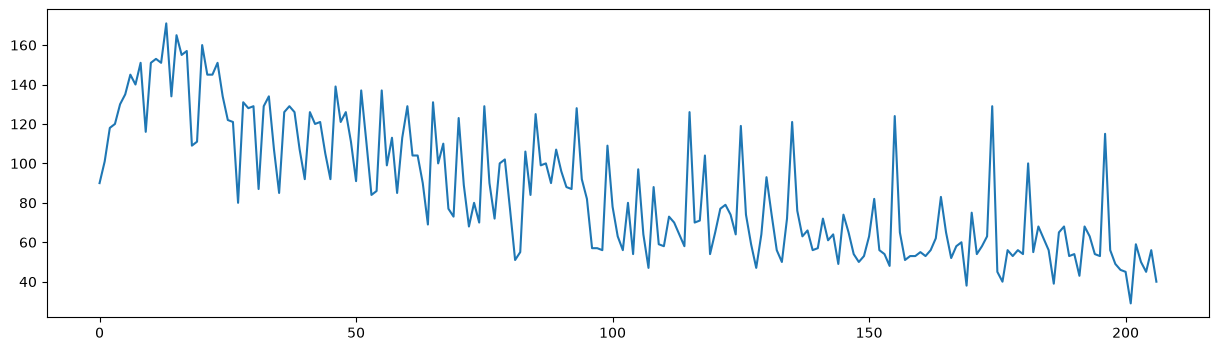

In [14]:
train["y"].plot(figsize=(15,4))
#売上のグラフ化

C:\Users\NDY13\AppData\Local\Temp\ipykernel_21120\1246012862.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[1][0].set_xticklabels(ax[1][0].get_xticklabels(),rotation=30)
C:\Users\NDY13\AppData\Local\Temp\ipykernel_21120\1246012862.py:7: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_21120\1246012862.py:7: UserWarning: Glyph 28779 (\N{CJK UNIFIED IDEOGRAPH-706B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_21120\1246012862.py:7: UserWarning: Glyph 27700 (\N{CJK UNIFIED IDEOGRAPH-6C34}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\NDY13\AppData\Local\Temp\ipykernel_21120\1246012862.py:7: UserWarning: Glyph 26408 (\N{CJK UNIFIED IDEOGRAPH-6728}) missing from font(s) DejaVu Sans.
  p

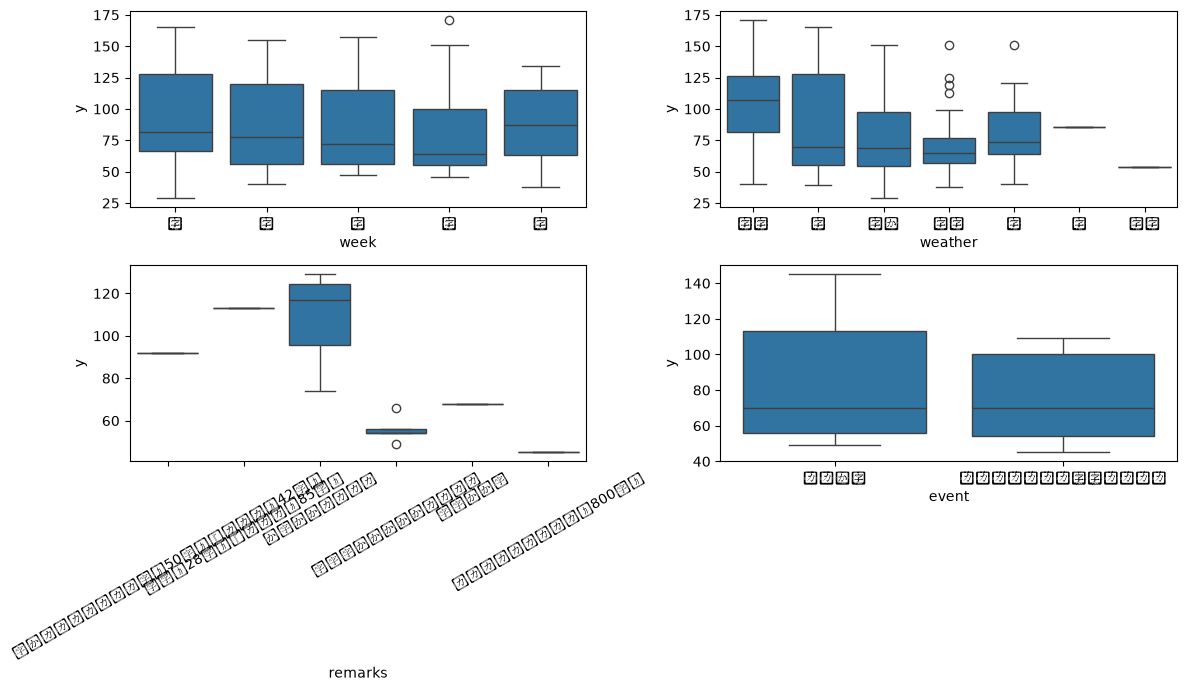

In [15]:
fig, ax = plt.subplots(2,2,figsize=(12,7))
sns.boxplot(x="week",y="y",data=train,ax=ax[0][0])
sns.boxplot(x="weather",y="y",data=train,ax=ax[0][1])
sns.boxplot(x="remarks",y="y",data=train,ax=ax[1][0])
ax[1][0].set_xticklabels(ax[1][0].get_xticklabels(),rotation=30)
sns.boxplot(x="event",y="y",data=train,ax=ax[1][1])
plt.tight_layout()
#グラフ化して、売上に影響を与える要素を確認する

In [16]:
all_data.loc[all_data['remarks'] != 'お楽しみメニュー', 'remarks'] = 'なし'
all_data['remarks'].unique()
#お楽しみメニューの有無を確認する
#欠損値を「なし」で補完する

<StringArray>
['なし', 'お楽しみメニュー']
Length: 2, dtype: str

In [17]:
all_data.info()
#欠損値がなくなったことを確認する

<class 'pandas.DataFrame'>
Index: 247 entries, 0 to 39
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   datetime       247 non-null    str    
 1   y              207 non-null    float64
 2   week           247 non-null    str    
 3   soldout        247 non-null    int64  
 4   name           247 non-null    str    
 5   kcal           247 non-null    float64
 6   remarks        247 non-null    str    
 7   event          17 non-null     str    
 8   payday         247 non-null    float64
 9   weather        247 non-null    str    
 10  precipitation  247 non-null    str    
 11  temperature    247 non-null    float64
 12  flg            247 non-null    int64  
dtypes: float64(4), int64(2), str(7)
memory usage: 27.0 KB


In [18]:
# 学習用データ
# 説明変数に "temperature (温度)" を利用
X_train = train['temperature']
# 目的変数に "y (売り上げ個数)" を利用
y_train = train['y']

# 検証用（予測用）データ
X_test  = test['temperature']

In [19]:
all_data['event'] = all_data['event'].fillna('なし')
all_data['event'].unique()
#eventの欠損値を「なし」で補完する

<StringArray>
['なし', 'ママの会', 'キャリアアップ支援セミナー']
Length: 3, dtype: str

In [20]:
X_train.head()

X_train.shape
# > (207,)

(207,)

In [21]:
X_train = X_train.values.reshape(-1,1)
X_test = X_test.values.reshape(-1,1)
#トレーニングデータとテストデータを一列データにする

In [22]:
print(X_train)
#X_trainを表示

[[19.8]
 [17. ]
 [15.5]
 [15.2]
 [16.1]
 [14.6]
 [17.9]
 [14.7]
 [17.7]
 [12.1]
 [13.8]
 [13.9]
 [13.5]
 [13.8]
 [14.9]
 [ 9.1]
 [ 7.1]
 [11. ]
 [12.3]
 [13.9]
 [11.3]
 [10.8]
 [ 7.8]
 [ 6.8]
 [ 8.4]
 [11.5]
 [ 8. ]
 [ 7.3]
 [ 7.3]
 [ 9.8]
 [10.9]
 [ 5.1]
 [ 5.8]
 [ 2.9]
 [ 7. ]
 [ 7.8]
 [ 6.5]
 [10.4]
 [ 7.4]
 [ 8.5]
 [10.1]
 [ 5.1]
 [12.6]
 [10.3]
 [15.3]
 [14.1]
 [15.9]
 [ 3.8]
 [ 3. ]
 [ 4.2]
 [ 5.5]
 [ 7.8]
 [ 6.3]
 [ 6.4]
 [ 1.2]
 [11.6]
 [ 6.8]
 [ 7.3]
 [ 5.4]
 [ 8.5]
 [ 6.6]
 [10.5]
 [11.5]
 [ 8.5]
 [17.7]
 [ 7.8]
 [ 8.3]
 [ 6.1]
 [ 6.7]
 [ 7. ]
 [ 7.6]
 [ 8.7]
 [14.8]
 [15.2]
 [11.5]
 [14. ]
 [18.9]
 [12.6]
 [ 7.5]
 [17.4]
 [18.9]
 [18.7]
 [12.4]
 [18.5]
 [17.5]
 [16.1]
 [18.2]
 [14.3]
 [17.8]
 [13.8]
 [20.1]
 [19. ]
 [21.3]
 [16.5]
 [16.4]
 [19.7]
 [21.5]
 [20.1]
 [11.4]
 [16.4]
 [18.8]
 [19.4]
 [19.9]
 [20.8]
 [22.7]
 [17.5]
 [24. ]
 [23.3]
 [18.9]
 [21. ]
 [23.4]
 [22.7]
 [18.6]
 [26. ]
 [19.3]
 [23.8]
 [22.8]
 [23.9]
 [17.4]
 [19. ]
 [19.8]
 [23.9]
 [23.7]
 [25.7]
 [26. ]


In [23]:
#X_testを表示
print(X_test)

[[20.2]
 [23.9]
 [28.7]
 [21.5]
 [22.1]
 [23.3]
 [22.5]
 [26.1]
 [26.8]
 [15.6]
 [18.6]
 [23. ]
 [23.9]
 [20.2]
 [15.5]
 [14.7]
 [18.7]
 [22.7]
 [19.1]
 [19.6]
 [19.6]
 [18.8]
 [18.9]
 [16. ]
 [19.2]
 [20.1]
 [21.2]
 [14.7]
 [14.4]
 [19.5]
 [15.8]
 [14.3]
 [16.1]
 [14.9]
 [10.5]
 [14.9]
 [11.4]
 [ 9.2]
 [15.1]
 [15.3]]


In [24]:
X_train.shape
#行数と列数を確認

(207, 1)

In [25]:
%pip install Cython
import sklearn
sklearn.set_config(display="text")
%pip install scikit-learn
from sklearn.linear_model import LinearRegression as LR 
%matplotlib inline 
# 線形回帰のモデルインポート

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [26]:
model = LR()
#モデルを代入

In [27]:
model.fit(X_train, y_train)
#データを学習させる

LinearRegression()

In [28]:
model.coef_ #傾き
# > array([-2.5023821])

model.intercept_ #切片
# > 134.79948383749922

np.float64(134.79948383749922)

In [29]:
# 検証（決定係数の計算）
model.score(X_train, y_train)

# > 0.4294602815194137

0.42946028151941373

In [30]:
pred = model.predict(X_test)
print(pred)
#予測実行

[ 84.25136537  74.99255159  62.9811175   80.99826864  79.49683938
  76.49398085  78.49588653  69.48731097  67.73564349  95.76232304
  88.25517673  77.24469548  74.99255159  84.25136537  96.01256125
  98.01446693  88.00493852  77.99541011  87.00398568  85.75279463
  85.75279463  87.75470031  87.5044621   94.7613702   86.75374747
  84.50160358  81.74898327  98.01446693  98.76518156  86.00303284
  95.26184662  99.01541977  94.51113199  97.51399051 108.52447176
  97.51399051 106.27232787 111.7775685   97.01351409  96.51303767]


In [31]:
sample.head()
#サンプルを確認

,0,1
0,2014-10-1,24
1,2014-10-2,71
2,2014-10-3,25
3,2014-10-6,32
4,2014-10-7,60


In [32]:
sample[1] = pred
sample.head()
#sampleファイルを上書きする

,0,1
0,2014-10-1,84.251365
1,2014-10-2,74.992552
2,2014-10-3,62.981117
3,2014-10-6,80.998269
4,2014-10-7,79.496839


In [33]:
sample.to_csv('submit1.csv', index=None, header=None)
#sampleファイルをcsv化する